In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings 
warnings.filterwarnings("ignore")

In [2]:
file_path = r"D:\Customer Segmentation Analysis\data\raw\customer_segmentation_dataset.xlsx"

# read workbook
excel_data = pd.ExcelFile(file_path)

print("Available Sheets: ")
print(excel_data.sheet_names)

Available Sheets: 
['Customers', 'Transactions', 'Products', 'Annual Summary']


In [6]:
# Loading sheets

customers = pd.read_excel(file_path, sheet_name = "Customers")
transactions = pd.read_excel(file_path, sheet_name = "Transactions")
products = pd.read_excel(file_path, sheet_name = "Products")
annual_summary = pd.read_excel(file_path, sheet_name = "Annual Summary")

print("All datasets loaded successfully")

All datasets loaded successfully


In [7]:
print("Customers: ", customers.shape)
print("Transactions: ", transactions.shape)
print("Products: ", products.shape)
print("Annual Summary: ", annual_summary.shape)

Customers:  (6500, 6)
Transactions:  (32500, 9)
Products:  (18, 4)
Annual Summary:  (5, 7)


In [8]:
display(customers.head())
display(transactions.head())
display(products.head())
display(annual_summary.head())

,CustomerID,SignupDate,Region,Country,AcquisitionChannel,ReferenceGroup
0,C00001,2024-09-20,South,Nepal,In-Store,Occasional Buyers
1,C00002,2021-11-08,West,Nepal,Mobile App,Regular Customers
2,C00003,2022-07-15,East,Bangladesh,Website,Occasional Buyers
3,C00004,2022-05-06,North,Nepal,In-Store,Seasonal Buyers
4,C00005,2021-02-02,Central,India,Website,At Risk


,TransactionID,CustomerID,OrderDate,ProductID,Quantity,UnitPrice,Discount,Sales,Profit
0,T004738,C00837,2021-01-04,P004,4,127.04,0.15,431.94,226.28
1,T017137,C00700,2021-01-04,P003,1,155.25,0.15,131.96,54.07
2,T007957,C05879,2021-01-06,P010,2,83.82,0.05,159.26,59.54
3,T014421,C01707,2021-01-06,P003,1,155.25,0.15,131.96,63.44
4,T010989,C04394,2021-01-07,P018,3,16.17,0.00,48.51,23.66


,ProductID,ProductName,Category,UnitPrice
0,P001,Wireless Mouse,Electronics,140.44
1,P002,Bluetooth Speaker,Electronics,81.80
2,P003,USB-C Cable,Electronics,155.25
3,P004,Water Bottle,Home & Kitchen,127.04
4,P005,Coffee Maker,Home & Kitchen,21.48


,Year,TotalTransactions,UniqueCustomers,TotalRevenue,TotalProfit,TotalQuantity,AverageOrderValue
0,2021,1543,907,438385.02,162422.43,4574,284.11
1,2022,4091,1913,1177692.17,426322.16,12312,287.87
2,2023,6429,2717,1855222.36,677537.30,19283,288.57
3,2024,9228,3550,2664583.38,976037.59,27753,288.75
4,2025,11209,4248,3234576.01,1177389.79,33673,288.57


In [9]:
# Column Names:

print("Customers Columns:")
print(customers.columns.tolist())

print("\nTransactions Columns:")
print(transactions.columns.tolist())

print("\nProducts Columns:")
print(products.columns.tolist())

print("\nAnnual Summary Columns:")
print(annual_summary.columns.tolist())

Customers Columns:
['CustomerID', 'SignupDate', 'Region', 'Country', 'AcquisitionChannel', 'ReferenceGroup']

Transactions Columns:
['TransactionID', 'CustomerID', 'OrderDate', 'ProductID', 'Quantity', 'UnitPrice', 'Discount', 'Sales', 'Profit']

Products Columns:
['ProductID', 'ProductName', 'Category', 'UnitPrice']

Annual Summary Columns:
['Year', 'TotalTransactions', 'UniqueCustomers', 'TotalRevenue', 'TotalProfit', 'TotalQuantity', 'AverageOrderValue']


In [10]:
# Checking Data types

print("CUSTOMERS DATA TYPES")
print(customers.dtypes)

print("\nTRANSACTIONS DATA TYPES")
print(transactions.dtypes)

print("\nPRODUCTS DATA TYPES")
print(products.dtypes)

print("\nANNUAL SUMMARY DATA TYPES")
print(annual_summary.dtypes)

CUSTOMERS DATA TYPES
CustomerID                       str
SignupDate            datetime64[us]
Region                           str
Country                          str
AcquisitionChannel               str
ReferenceGroup                   str
dtype: object

TRANSACTIONS DATA TYPES
TransactionID               str
CustomerID                  str
OrderDate        datetime64[us]
ProductID                   str
Quantity                  int64
UnitPrice               float64
Discount                float64
Sales                   float64
Profit                  float64
dtype: object

PRODUCTS DATA TYPES
ProductID          str
ProductName        str
Category           str
UnitPrice      float64
dtype: object

ANNUAL SUMMARY DATA TYPES
Year                   int64
TotalTransactions      int64
UniqueCustomers        int64
TotalRevenue         float64
TotalProfit          float64
TotalQuantity          int64
AverageOrderValue    float64
dtype: object


In [11]:
# Missing values:

print("CUSTOMERS MISSING VALUES")
print(customers.isnull().sum())

print("\nTRANSACTIONS MISSING VALUES")
print(transactions.isnull().sum())

print("\nPRODUCTS MISSING VALUES")
print(products.isnull().sum())

print("\nANNUAL SUMMARY MISSING VALUES")
print(annual_summary.isnull().sum())

CUSTOMERS MISSING VALUES
CustomerID            0
SignupDate            0
Region                0
Country               0
AcquisitionChannel    0
ReferenceGroup        0
dtype: int64

TRANSACTIONS MISSING VALUES
TransactionID    0
CustomerID       0
OrderDate        0
ProductID        0
Quantity         0
UnitPrice        0
Discount         0
Sales            0
Profit           0
dtype: int64

PRODUCTS MISSING VALUES
ProductID      0
ProductName    0
Category       0
UnitPrice      0
dtype: int64

ANNUAL SUMMARY MISSING VALUES
Year                 0
TotalTransactions    0
UniqueCustomers      0
TotalRevenue         0
TotalProfit          0
TotalQuantity        0
AverageOrderValue    0
dtype: int64


In [12]:
# Duplicate records:

print("Customers Duplicates:", customers.duplicated().sum())

print("Transactions Duplicates:", transactions.duplicated().sum())

print("Products Duplicates:", products.duplicated().sum())

print("Annual Summary Duplicates:", annual_summary.duplicated().sum())

Customers Duplicates: 0
Transactions Duplicates: 0
Products Duplicates: 0
Annual Summary Duplicates: 0


In [13]:
# Descriptive records:

print("CUSTOMERS MISSING VALUES")
print(customers.isnull().sum())

print("\nTRANSACTIONS MISSING VALUES")
print(transactions.isnull().sum())

print("\nPRODUCTS MISSING VALUES")
print(products.isnull().sum())

print("\nANNUAL SUMMARY MISSING VALUES")
print(annual_summary.isnull().sum())

CUSTOMERS MISSING VALUES
CustomerID            0
SignupDate            0
Region                0
Country               0
AcquisitionChannel    0
ReferenceGroup        0
dtype: int64

TRANSACTIONS MISSING VALUES
TransactionID    0
CustomerID       0
OrderDate        0
ProductID        0
Quantity         0
UnitPrice        0
Discount         0
Sales            0
Profit           0
dtype: int64

PRODUCTS MISSING VALUES
ProductID      0
ProductName    0
Category       0
UnitPrice      0
dtype: int64

ANNUAL SUMMARY MISSING VALUES
Year                 0
TotalTransactions    0
UniqueCustomers      0
TotalRevenue         0
TotalProfit          0
TotalQuantity        0
AverageOrderValue    0
dtype: int64


In [14]:
# Unique values:

print("Unique Customers:", customers["CustomerID"].nunique())

print("Unique Transactions:", transactions["TransactionID"].nunique())

print("Unique Products:", products["ProductID"].nunique())

Unique Customers: 6500
Unique Transactions: 32500
Unique Products: 18


In [15]:
# customer acquisition channels:
print(customers["AcquisitionChannel"].value_counts())

AcquisitionChannel
Website           1828
Mobile App        1742
Social Media       980
Email Campaign     849
Referral           578
In-Store           523
Name: count, dtype: int64


In [16]:
# prodduct categories:
print(products["Category"].value_counts())

Category
Electronics       3
Home & Kitchen    3
Fashion           3
Beauty            3
Sports            3
Books             3
Name: count, dtype: int64


In [17]:
# transaction date range
transactions["OrderDate"] = pd.to_datetime(transactions["OrderDate"])
print("First Transaction Date:", transactions["OrderDate"].min())
print("Last Transaction Date:", transactions["OrderDate"].max())

First Transaction Date: 2021-01-04 00:00:00
Last Transaction Date: 2025-12-31 00:00:00


In [18]:
# transaction distribution by year

transactions["Year"] = transactions["OrderDate"].dt.year
yearly_transactions = transactions["Year"].value_counts().sort_index()
display(yearly_transactions)

Year
2021     1543
2022     4091
2023     6429
2024     9228
2025    11209
Name: count, dtype: int64

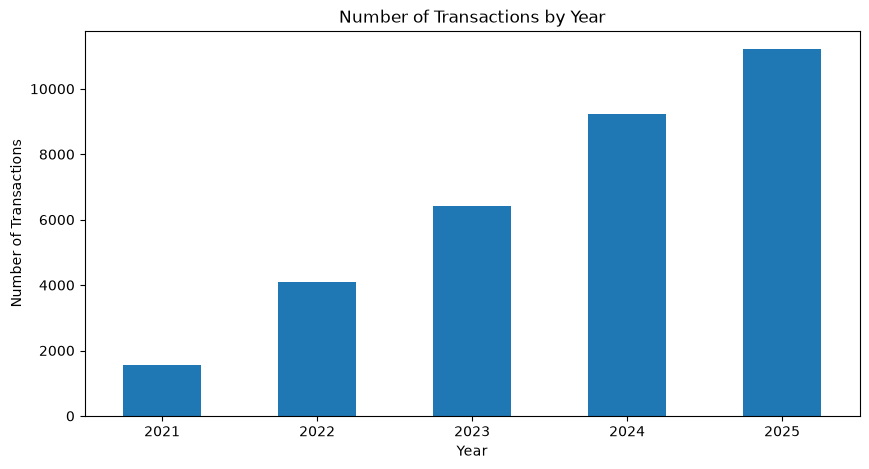

In [19]:
# visualizations:
plt.figure(figsize=(10, 5))

yearly_transactions.plot(kind="bar")

plt.title("Number of Transactions by Year")
plt.xlabel("Year")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)

plt.show()

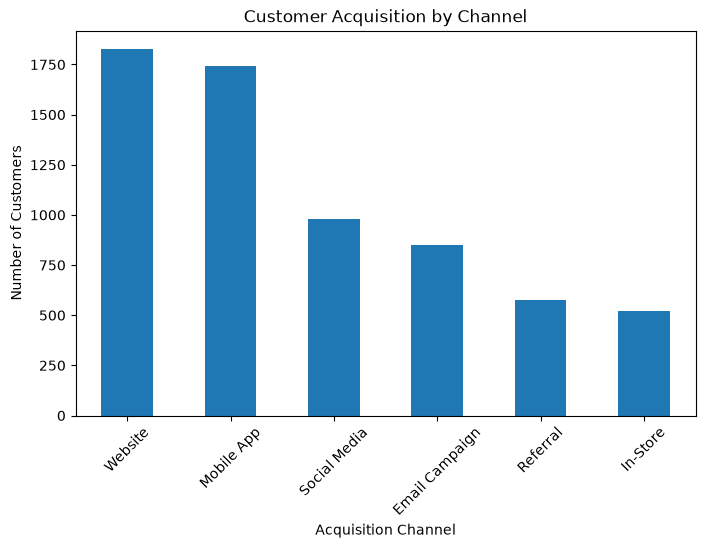

In [20]:
# customer acquisition channels

channel_counts = customers["AcquisitionChannel"].value_counts()
plt.figure(figsize=(8, 5))
channel_counts.plot(kind="bar")
plt.title("Customer Acquisition by Channel")
plt.xlabel("Acquisition Channel")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.show()

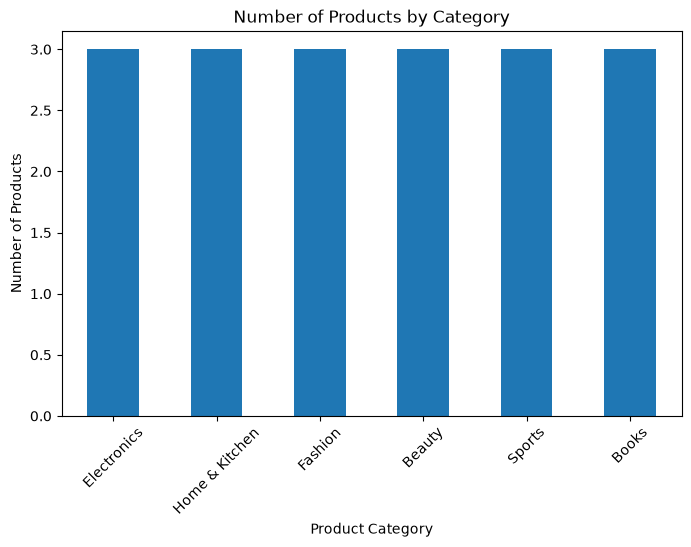

In [21]:
# product categories

category_counts = products["Category"].value_counts()
plt.figure(figsize=(8, 5))
category_counts.plot(kind="bar")
plt.title("Number of Products by Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)

plt.show()

In [23]:
# Transaction metrics

total_transactions = transactions["TransactionID"].nunique()

total_customers = customers["CustomerID"].nunique()

total_products = products["ProductID"].nunique()

total_revenue = transactions["Sales"].sum()

average_transaction_value = transactions["Sales"].mean()

print("Total Transactions:", total_transactions)
print("Total Customers:", total_customers)
print("Total Products:", total_products)
print("Total Revenue:", round(total_revenue, 2))
print("Average Transaction Value:", round(average_transaction_value, 2))

Total Transactions: 32500
Total Customers: 6500
Total Products: 18
Total Revenue: 9370458.94
Average Transaction Value: 288.32


In [24]:
# active and inacctive customers

active_customers = transactions["CustomerID"].nunique()

total_customers = customers["CustomerID"].nunique()

inactive_customers = total_customers - active_customers

print("Total Customers:", total_customers)
print("Active Customers:", active_customers)
print("Customers Without Purchases:", inactive_customers)


Total Customers: 6500
Active Customers: 6232
Customers Without Purchases: 268


In [25]:
# customer distribution

customer_status = pd.Series({
    "Active Customers": active_customers,
    "Customers Without Purchases": inactive_customers
})

display(customer_status)

Active Customers               6232
Customers Without Purchases     268
dtype: int64

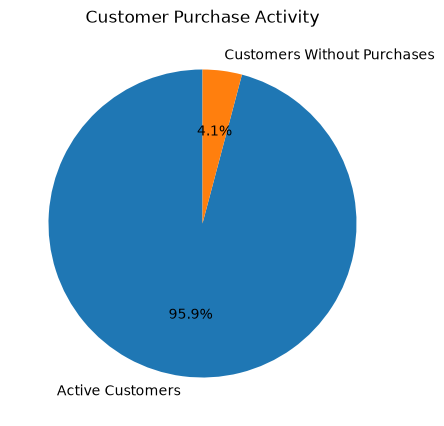

In [26]:
# customer distribution figure:

plt.figure(figsize=(7, 5))

plt.pie(
    customer_status,
    labels=customer_status.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Purchase Activity")

plt.show()

In [27]:
# yearly sales
transactions["Year"] = transactions["OrderDate"].dt.year

yearly_sales = transactions.groupby("Year")["Sales"].sum()

display(yearly_sales)

Year
2021     438385.02
2022    1177692.17
2023    1855222.36
2024    2664583.38
2025    3234576.01
Name: Sales, dtype: float64

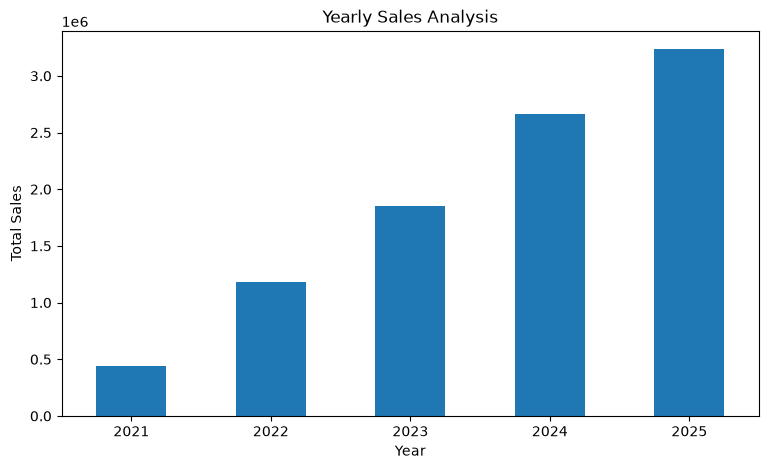

In [28]:
# yearly sales visualization:

plt.figure(figsize=(9, 5))

yearly_sales.plot(kind="bar")

plt.title("Yearly Sales Analysis")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)

plt.show()